# 04 Calibration and neural network tuning

## Purpose
The first model comparison (`03_models`) showed that the neural network was weaker than logistic regression and XGBoost. Its ROC-AUC was 0.744 against 0.781, and its Brier score was 0.220 against about 0.17. At the cost-based threshold of 1/6 it cost 0.769 per customer, which is worse than the 0.7 obtained by refusing every applicant. This notebook investigates why and tests a simple fix.

## Why calibration matters
The 1/6 threshold comes from the 5:1 cost matrix. The model should refuse an applicant when the predicted probability of bad credit is above 1/6. This rule only works if the predicted probabilities are close to the real frequencies, which is what calibration measures. A model with good ranking (ROC-AUC) but poorly calibrated probabilities can still give a poor cost.

## Step 1: calibration plot
Out-of-fold probabilities are collected for all three models using 5-fold stratified cross-validation, and each model is plotted against the diagonal of perfect calibration. The preprocessing sits inside the pipeline, so it is fitted on the training part of each fold only and there is no data leakage. A curve that is flatter or more S-shaped than the diagonal means the probabilities are too extreme.

## Step 2: tuning the number of epochs and learning rate
The first network was trained for 100 epochs with no regularisation on only 1,000 records, so it probably overfits. This step tries fewer epochs and two learning rates, using one cross-validation repeat for speed. The measures to watch are the Brier score (lower is better), ROC-AUC and the expected cost at 1/6.

## Limitations
- The settings are chosen on the same folds that are reported, so the results are slightly optimistic. Nested cross-validation is planned to remove this.
- The sweep is small and only changes two settings. It is a first check, not a full search.
- One repeat gives noisier estimates than the 5 x 3 cross-validation used in the main comparison.

## Outputs
- `results/calibration.png`: calibration curves for the three models
- `results/nn_tuning.csv`: results for each epoch and learning rate setting

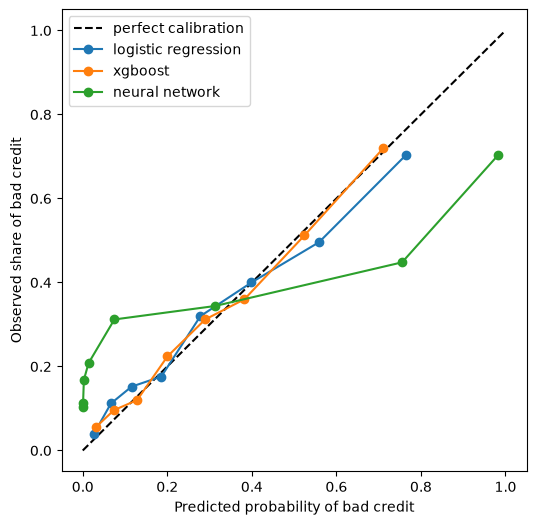

In [1]:
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.config import SEED
from src.data import load_data
from src.models import TorchMLP
from src.preprocess import build_preprocessor

X, y = load_data()

def make(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

models = {
    "logistic regression": make(LogisticRegression(max_iter=1000)),
    "xgboost": make(XGBClassifier(n_estimators=200, max_depth=3,
                                  learning_rate=0.05, random_state=SEED)),
    "neural network": make(TorchMLP()),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
for name, m in models.items():
    p = cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1]
    frac, mean_p = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=name)
ax.set_xlabel("Predicted probability of bad credit")
ax.set_ylabel("Observed share of bad credit")
ax.legend()
plt.savefig("../results/calibration.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
import pandas as pd
from src.evaluate import cross_validate

rows = {}
for epochs in (10, 20, 40, 70):
    for lr in (1e-3, 3e-3):
        m = make(TorchMLP(epochs=epochs, lr=lr))
        r = cross_validate(m, X, y, n_repeats=1).mean()
        rows[f"epochs={epochs}, lr={lr}"] = r
tuning = pd.DataFrame(rows).T.round(3)
tuning[["roc_auc", "brier", "cost_at_0.5", "cost_at_1/6"]]

tuning.to_csv("../results/nn_tuning.csv")
tuning[["roc_auc", "brier", "cost_at_0.5", "cost_at_1/6"]].to_csv("../results/nn_tuning_short.csv")